# Esquema de memoria: colección

## Repaso

Ampliamos nuestro chatbot para que guarde memorias semánticas en un único [perfil de usuario](https://docs.langchain.com/oss/python/concepts/memory#profile).

También presentamos una biblioteca, [Trustcall](https://github.com/hinthornw/trustcall), para actualizar este esquema con información nueva.

## Objetivos

A veces queremos guardar las memorias en una [colección](https://docs.google.com/presentation/d/181mvjlgsnxudQI6S3ritg9sooNyu4AcLLFH1UK0kIuk/edit#slide=id.g30eb3c8cf10_0_200) en vez de en un único perfil.

Aquí actualizaremos nuestro chatbot para [guardar las memorias en una colección](https://docs.langchain.com/oss/python/concepts/memory#collection).

También mostraremos cómo usar Trustcall para actualizar esa colección.

In [ ]:
%%capture --no-stderr
%pip install -U langchain_openai langgraph trustcall langchain_core

In [1]:
import os, getpass

def _definir_variable(variable: str):
    # Revisamos si la variable está definida en el entorno del sistema operativo
    valor_entorno = os.environ.get(variable)
    if not valor_entorno:
        # Si no está definida, se la pedimos al usuario
        valor_entorno = getpass.getpass(f"{variable}: ")

    # Definimos la variable de entorno para el proceso actual
    os.environ[variable] = valor_entorno

_definir_variable("LANGSMITH_API_KEY")
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_PROJECT"] = "langchain-academy"

## Definir un esquema de colección

En vez de guardar la información del usuario en un perfil de estructura fija, crearemos un esquema de colección flexible para guardar memorias sobre las interacciones con el usuario.

Cada memoria se guardará como una entrada separada, con un único campo `contenido` para la información principal que queremos recordar.

Este enfoque nos permite construir una colección abierta de memorias que puede crecer y cambiar a medida que aprendemos más sobre el usuario.

Podemos definir un esquema de colección como un objeto de [Pydantic](https://docs.pydantic.dev/latest/).

In [2]:
from pydantic import BaseModel, Field

class Memoria(BaseModel):
    contenido: str = Field(description="El contenido principal de la memoria. Por ejemplo: El usuario expresó interés en aprender francés.")

class ColeccionMemorias(BaseModel):
    memorias: list[Memoria] = Field(description="Una lista de memorias sobre el usuario.")

In [3]:
_definir_variable("OPENAI_API_KEY")

Podemos usar el método [`with_structured_output`](https://docs.langchain.com/oss/python/langchain/models#structured-outputs) de la interfaz de [modelo de chat](https://docs.langchain.com/oss/python/langchain/models) de LangChain para forzar una salida estructurada.

In [3]:
from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI

# Inicializamos el modelo
modelo = ChatOpenAI(model="gpt-4o", temperature=0)

# Vinculamos el esquema al modelo
modelo_con_estructura = modelo.with_structured_output(ColeccionMemorias)

# Invocamos el modelo para producir una salida estructurada que coincida con el esquema
coleccion_memorias = modelo_con_estructura.invoke([HumanMessage("Me llamo Lance. Me gusta andar en bicicleta.")])
coleccion_memorias.memorias

[Memory(content="User's name is Lance."),
 Memory(content='Lance likes to bike.')]

Podemos usar `model_dump()` para serializar una instancia de un modelo de Pydantic en un diccionario de Python.

In [4]:
coleccion_memorias.memorias[0].model_dump()

{'content': "User's name is Lance."}

Guardamos en el Store la representación en diccionario de cada memoria.

In [5]:
import uuid
from langgraph.store.memory import InMemoryStore

# Inicializamos el Store en memoria
store_en_memoria = InMemoryStore()

# Namespace de la memoria que vamos a guardar
id_usuario = "1"
namespace_para_memoria = (id_usuario, "memorias")

# Guardamos una memoria en el namespace con una clave y un valor
clave = str(uuid.uuid4())
valor = coleccion_memorias.memorias[0].model_dump()
store_en_memoria.put(namespace_para_memoria, clave, valor)

clave = str(uuid.uuid4())
valor = coleccion_memorias.memorias[1].model_dump()
store_en_memoria.put(namespace_para_memoria, clave, valor)

Buscamos las memorias en el Store.

In [6]:
# Búsqueda
for m in store_en_memoria.search(namespace_para_memoria):
    print(m.dict())

{'value': {'content': "User's name is Lance."}, 'key': 'e1c4e5ab-ab0f-4cbb-822d-f29240a983af', 'namespace': ['1', 'memories'], 'created_at': '2024-10-30T21:43:26.893775+00:00', 'updated_at': '2024-10-30T21:43:26.893779+00:00'}
{'value': {'content': 'Lance likes to bike.'}, 'key': 'e132a1ea-6202-43ac-a9a6-3ecf2c1780a8', 'namespace': ['1', 'memories'], 'created_at': '2024-10-30T21:43:26.893833+00:00', 'updated_at': '2024-10-30T21:43:26.893834+00:00'}


## Actualizar un esquema de colección

En la lección anterior vimos las dificultades de actualizar un esquema de perfil.

¡Lo mismo vale para las colecciones!

Queremos poder actualizar la colección con memorias nuevas y también actualizar las memorias que ya existen en ella.

Ahora mostraremos que [Trustcall](https://github.com/hinthornw/trustcall) también sirve para actualizar una colección.

Esto permite tanto agregar memorias nuevas como [actualizar las memorias existentes de la colección](https://github.com/hinthornw/trustcall?tab=readme-ov-file#simultanous-updates--insertions
).

Definamos un extractor nuevo con Trustcall.

Como antes, entregamos el esquema de cada memoria, `Memoria`.

Pero podemos pasar `enable_inserts=True` para permitir que el extractor inserte memorias nuevas en la colección.

In [85]:
from trustcall import create_extractor

# Creamos el extractor
extractor_trustcall = create_extractor(
    modelo,
    tools=[Memoria],
    tool_choice="Memoria",
    enable_inserts=True,
)

In [105]:
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage

# Instrucción
instruccion = """Extrae memorias de la siguiente conversación:"""

# Conversación
conversacion = [HumanMessage(content="Hola, soy Lance."),
                AIMessage(content="Mucho gusto, Lance."),
                HumanMessage(content="Esta mañana salí a andar en bicicleta por San Francisco.")]

# Invocamos el extractor
resultado = extractor_trustcall.invoke({"messages": [SystemMessage(content=instruccion)] + conversacion})

In [106]:
# Los mensajes contienen las llamadas a herramientas
for m in resultado["messages"]:
    m.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  Memory (call_Pj4kctFlpg9TgcMBfMH33N30)
 Call ID: call_Pj4kctFlpg9TgcMBfMH33N30
  Args:
    content: Lance had a nice bike ride in San Francisco this morning.


In [107]:
# Las respuestas contienen las memorias que cumplen el esquema
for m in resultado["responses"]:
    print(m)

content='Lance had a nice bike ride in San Francisco this morning.'


In [108]:
# Los metadatos contienen la llamada a la herramienta
for m in resultado["response_metadata"]:
    print(m)

{'id': 'call_Pj4kctFlpg9TgcMBfMH33N30'}


In [109]:
# Actualizamos la conversación
conversacion_actualizada = [AIMessage(content="Qué bien, ¿qué hiciste después?"),
                            HumanMessage(content="Fui a Tartine y comí un croissant."),
                            AIMessage(content="¿Qué más tienes en mente?"),
                            HumanMessage(content="¡Estaba pensando en mi viaje a Japón, y en volver este invierno!"),]

# Actualizamos la instrucción
mensaje_sistema = """Actualiza las memorias existentes y crea otras nuevas a partir de la siguiente conversación:"""

# Guardaremos las memorias existentes, dándoles un id, una clave (nombre de la herramienta) y un valor
nombre_herramienta = "Memoria"
memorias_existentes = [(str(i), nombre_herramienta, memoria.model_dump()) for i, memoria in enumerate(resultado["responses"])] if resultado["responses"] else None
memorias_existentes

[('0',
  'Memory',
  {'content': 'Lance had a nice bike ride in San Francisco this morning.'})]

In [110]:
# Invocamos el extractor con nuestra conversación actualizada y las memorias existentes
resultado = extractor_trustcall.invoke({"messages": conversacion_actualizada,
                                        "existing": memorias_existentes})

In [111]:
# Los mensajes del modelo indican que se hicieron dos llamadas a herramientas
for m in resultado["messages"]:
    m.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  Memory (call_vxks0YH1hwUxkghv4f5zdkTr)
 Call ID: call_vxks0YH1hwUxkghv4f5zdkTr
  Args:
    content: Lance had a nice bike ride in San Francisco this morning. He went to Tartine and ate a croissant. He was thinking about his trip to Japan and going back this winter!
  Memory (call_Y4S3poQgFmDfPy2ExPaMRk8g)
 Call ID: call_Y4S3poQgFmDfPy2ExPaMRk8g
  Args:
    content: Lance went to Tartine and ate a croissant. He was thinking about his trip to Japan and going back this winter!


In [112]:
# Las respuestas contienen las memorias que cumplen el esquema
for m in resultado["responses"]:
    print(m)

content='Lance had a nice bike ride in San Francisco this morning. He went to Tartine and ate a croissant. He was thinking about his trip to Japan and going back this winter!'
content='Lance went to Tartine and ate a croissant. He was thinking about his trip to Japan and going back this winter!'


Esto nos dice que actualizamos la primera memoria de la colección al especificar el `json_doc_id`.

In [113]:
# Los metadatos contienen la llamada a la herramienta
for m in resultado["response_metadata"]:
    print(m)

{'id': 'call_vxks0YH1hwUxkghv4f5zdkTr', 'json_doc_id': '0'}
{'id': 'call_Y4S3poQgFmDfPy2ExPaMRk8g'}


Traza de LangSmith:

https://smith.langchain.com/public/ebc1cb01-f021-4794-80c0-c75d6ea90446/r

## Chatbot con actualización del esquema de colección

Ahora incorporemos Trustcall a nuestro chatbot para crear y actualizar una colección de memorias.

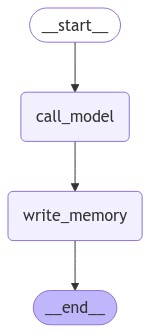

In [114]:
from IPython.display import Image, display

import uuid

from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.store.memory import InMemoryStore
from langchain_core.messages import merge_message_runs
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.runnables.config import RunnableConfig
from langgraph.checkpoint.memory import MemorySaver
from langgraph.store.base import BaseStore

# Inicializamos el modelo
modelo = ChatOpenAI(model="gpt-4o", temperature=0)

# Esquema de memoria
class Memoria(BaseModel):
    contenido: str = Field(description="El contenido principal de la memoria. Por ejemplo: El usuario expresó interés en aprender francés.")

# Creamos el extractor de Trustcall
extractor_trustcall = create_extractor(
    modelo,
    tools=[Memoria],
    tool_choice="Memoria",
    # Esto permite que el extractor inserte memorias nuevas
    enable_inserts=True,
)

# Instrucción del chatbot
MENSAJE_SISTEMA_MODELO = """Eres un chatbot útil. Estás diseñado para ser un compañero del usuario.

Tienes una memoria a largo plazo que lleva el registro de la información que aprendes sobre el usuario con el tiempo.

Memoria actual (puede incluir memorias actualizadas durante esta conversación):

{memoria}"""

# Instrucción de Trustcall
INSTRUCCION_TRUSTCALL = """Reflexiona sobre la siguiente interacción.

Usa las herramientas disponibles para conservar las memorias necesarias sobre el usuario.

Usa llamadas a herramientas en paralelo para manejar las actualizaciones y las inserciones al mismo tiempo:"""

def llamar_modelo(estado: MessagesState, config: RunnableConfig, store: BaseStore):

    """Carga las memorias desde el Store y las usa para personalizar la respuesta del chatbot."""

    # Obtenemos el id del usuario desde la configuración
    id_usuario = config["configurable"]["id_usuario"]

    # Recuperamos la memoria desde el Store
    namespace = ("memorias", id_usuario)
    memorias = store.search(namespace)

    # Damos formato a las memorias para el mensaje de sistema
    informacion = "\n".join(f"- {mem.value['contenido']}" for mem in memorias)
    mensaje_sistema = MENSAJE_SISTEMA_MODELO.format(memoria=informacion)

    # Respondemos usando la memoria y el historial del chat
    respuesta = modelo.invoke([SystemMessage(content=mensaje_sistema)]+estado["messages"])

    return {"messages": respuesta}

def escribir_memoria(estado: MessagesState, config: RunnableConfig, store: BaseStore):

    """Reflexiona sobre el historial del chat y actualiza la colección de memorias."""

    # Obtenemos el id del usuario desde la configuración
    id_usuario = config["configurable"]["id_usuario"]

    # Definimos el namespace de las memorias
    namespace = ("memorias", id_usuario)

    # Recuperamos las memorias más recientes como contexto
    elementos_existentes = store.search(namespace)

    # Damos formato a las memorias existentes para el extractor de Trustcall
    nombre_herramienta = "Memoria"
    memorias_existentes = ([(elemento_existente.key, nombre_herramienta, elemento_existente.value)
                            for elemento_existente in elementos_existentes]
                            if elementos_existentes
                            else None
                          )

    # Combinamos el historial del chat y la instrucción
    mensajes_actualizados=list(merge_message_runs(messages=[SystemMessage(content=INSTRUCCION_TRUSTCALL)] + estado["messages"]))

    # Invocamos el extractor
    resultado = extractor_trustcall.invoke({"messages": mensajes_actualizados,
                                            "existing": memorias_existentes})

    # Guardamos en el Store las memorias de Trustcall
    for r, meta_r in zip(resultado["responses"], resultado["response_metadata"]):
        store.put(namespace,
                  meta_r.get("json_doc_id", str(uuid.uuid4())),
                  r.model_dump(mode="json"),
            )

# Definimos el grafo
constructor = StateGraph(MessagesState)
constructor.add_node("llamar_modelo", llamar_modelo)
constructor.add_node("escribir_memoria", escribir_memoria)
constructor.add_edge(START, "llamar_modelo")
constructor.add_edge("llamar_modelo", "escribir_memoria")
constructor.add_edge("escribir_memoria", END)

# Store para la memoria a largo plazo (entre hilos)
memoria_entre_hilos = InMemoryStore()

# Checkpointer para la memoria a corto plazo (dentro del hilo)
memoria_del_hilo = MemorySaver()

# Compilamos el grafo con el checkpointer y el Store
grafo = constructor.compile(checkpointer=memoria_del_hilo, store=memoria_entre_hilos)

# Visualización
display(Image(grafo.get_graph(xray=1).draw_mermaid_png()))

In [115]:
# Entregamos un id de hilo para la memoria a corto plazo (dentro del hilo)
# Entregamos un id de usuario para la memoria a largo plazo (entre hilos)
config = {"configurable": {"thread_id": "1", "id_usuario": "1"}}

# Entrada del usuario
mensajes_entrada = [HumanMessage(content="Hola, me llamo Lance")]

# Ejecutamos el grafo
for fragmento in grafo.stream({"messages": mensajes_entrada}, config, stream_mode="values"):
    fragmento["messages"][-1].pretty_print()

================================ Human Message =================================

Hi, my name is Lance
================================== Ai Message ==================================

Hi Lance! It's great to meet you. How can I assist you today?


In [116]:
# Entrada del usuario
mensajes_entrada = [HumanMessage(content="Me gusta andar en bicicleta por San Francisco")]

# Ejecutamos el grafo
for fragmento in grafo.stream({"messages": mensajes_entrada}, config, stream_mode="values"):
    fragmento["messages"][-1].pretty_print()

================================ Human Message =================================

I like to bike around San Francisco
================================== Ai Message ==================================

That sounds like a lot of fun! San Francisco has some beautiful routes for biking. Do you have a favorite trail or area you like to explore?


In [117]:
# Namespace de la memoria que vamos a guardar
id_usuario = "1"
namespace = ("memorias", id_usuario)
memorias = memoria_entre_hilos.search(namespace)
for m in memorias:
    print(m.dict())

{'value': {'content': "User's name is Lance."}, 'key': 'dee65880-dd7d-4184-8ca1-1f7400f7596b', 'namespace': ['memories', '1'], 'created_at': '2024-10-30T22:18:52.413283+00:00', 'updated_at': '2024-10-30T22:18:52.413284+00:00'}
{'value': {'content': 'User likes to bike around San Francisco.'}, 'key': '662195fc-8ea4-4f64-a6b6-6b86d9cb85c0', 'namespace': ['memories', '1'], 'created_at': '2024-10-30T22:18:56.597813+00:00', 'updated_at': '2024-10-30T22:18:56.597814+00:00'}


In [118]:
# Entrada del usuario
mensajes_entrada = [HumanMessage(content="También disfruto ir a panaderías")]

# Ejecutamos el grafo
for fragmento in grafo.stream({"messages": mensajes_entrada}, config, stream_mode="values"):
    fragmento["messages"][-1].pretty_print()

================================ Human Message =================================

I also enjoy going to bakeries
================================== Ai Message ==================================

Biking and bakeries make a great combination! Do you have a favorite bakery in San Francisco, or are you on the hunt for new ones to try?


Continuemos la conversación en un hilo nuevo.

In [119]:
# Entregamos un id de hilo para la memoria a corto plazo (dentro del hilo)
# Entregamos un id de usuario para la memoria a largo plazo (entre hilos)
config = {"configurable": {"thread_id": "2", "id_usuario": "1"}}

# Entrada del usuario
mensajes_entrada = [HumanMessage(content="¿Qué panaderías me recomiendas?")]

# Ejecutamos el grafo
for fragmento in grafo.stream({"messages": mensajes_entrada}, config, stream_mode="values"):
    fragmento["messages"][-1].pretty_print()

================================ Human Message =================================

What bakeries do you recommend for me?
================================== Ai Message ==================================

Since you enjoy biking around San Francisco, you might like to check out some of these bakeries that are both delicious and located in areas that are great for a bike ride:

1. **Tartine Bakery** - Located in the Mission District, it's famous for its bread and pastries. The area is vibrant and perfect for a leisurely ride.

2. **Arsicault Bakery** - Known for its incredible croissants, it's in the Richmond District, which offers a nice ride through Golden Gate Park.

3. **B. Patisserie** - Situated in Lower Pacific Heights, this bakery is renowned for its kouign-amann and other French pastries. The neighborhood is charming and bike-friendly.

4. **Mr. Holmes Bakehouse** - Famous for its cruffins, it's located in the Tenderloin, which is a bit more urban but still accessible by bike.

5.

### LangSmith

https://smith.langchain.com/public/c87543ec-b426-4a82-a3ab-94d01c01d9f4/r

## Studio

![Captura de pantalla de Studio, 30 de octubre de 2024](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/6732d0876d3daa19fef993ba_Screenshot%202024-11-11%20at%207.50.21%E2%80%AFPM.png)